### M3EXAM
Author: DIEGO F. REYES Y.

### Library  

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from pathlib import Path

### Read data

In [3]:
## Load dataset
df_xtrain = pd.read_csv("X_train_Kaggle.csv")
df_ytrain = pd.read_csv("y_train_Kaggle.csv")

df_xtest  = pd.read_csv("X_test_Kaggle.csv") 

In [4]:
df_xtrain.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  int64  
 1   sexo                   70000 non-null  str    
 2   region                 70000 non-null  str    
 3   nivel_educacion_madre  70000 non-null  str    
 4   peso_kg                66531 non-null  float64
 5   talla_cm               62951 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 3.2 MB


In [5]:
df_xtest.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             30000 non-null  int64  
 1   sexo                   30000 non-null  str    
 2   region                 30000 non-null  str    
 3   nivel_educacion_madre  30000 non-null  str    
 4   peso_kg                28517 non-null  float64
 5   talla_cm               27049 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.4 MB


In [6]:
df_ytrain.info( )

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   alerta_desnutricion  70000 non-null  int64
dtypes: int64(1)
memory usage: 547.0 KB


## Explore and prepare the data

### X_train

In [7]:
df_xtrain1=df_xtrain
df_xtrain1["alerta_desnutricion"]=df_ytrain["alerta_desnutricion"]


In [8]:
df_xtrain1.head()

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,alerta_desnutricion
0,0,F,Costa,Secundaria,2.243466,47.340072,0
1,11,M,Insular,Secundaria,6.157203,67.525274,0
2,22,M,Costa,Superior,9.781251,86.664662,0
3,4,F,Sierra,Primaria,2.972311,61.071857,0
4,-4,F,Costa,Primaria,NaN,50.898250,0


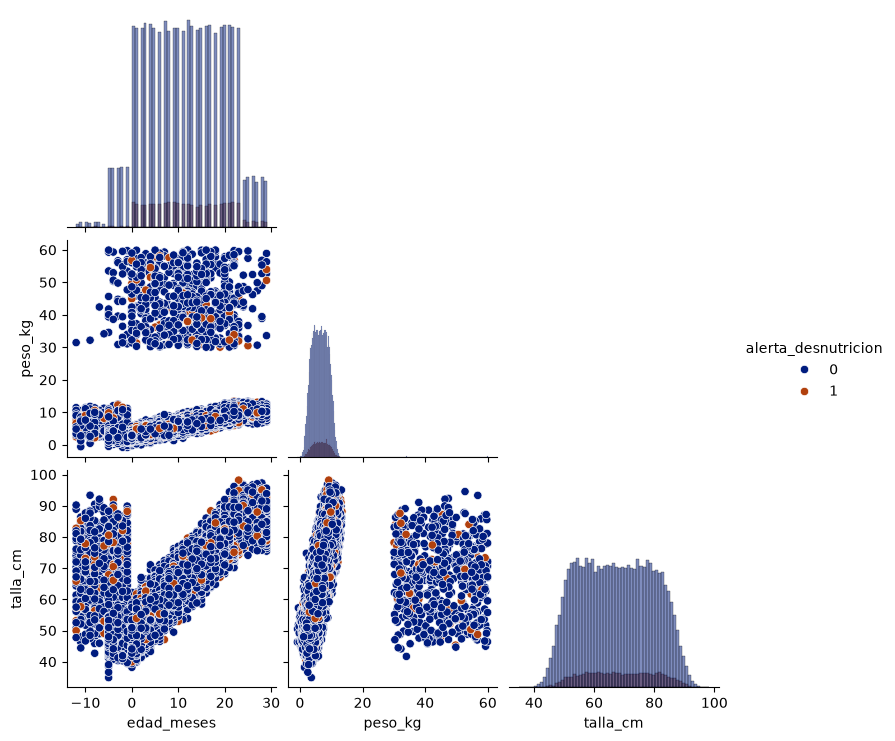

In [9]:
sns.pairplot(
    df_xtrain1,
    hue="alerta_desnutricion",
    palette="dark", 
    corner=True, 
    diag_kind="hist",  
)
plt.show()

edad_meses

=== ESTADÍSTICAS DE EDAD (MESES) ===
Mínimo (Min):      -12.00
Cuartil 1 (1Q):    5.00
Cuartil 2 (2Q):    11.00 (Mediana)
Cuartil 3 (3Q):    18.00
Cuartil 99 (99):    28.00
Máximo (Max):      29.00
------------------------------------
Media (Promedio):  11.46
Mediana (50%):     11.00


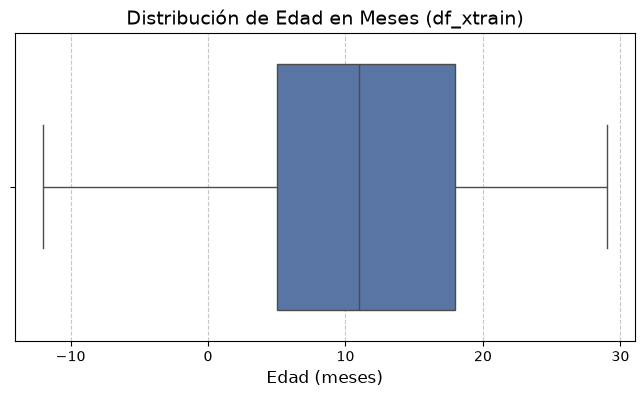

In [10]:
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtrain["edad_meses"].describe()
quantile_25 = df_xtrain["edad_meses"].quantile(0.25)
quantile_50 = df_xtrain["edad_meses"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtrain["edad_meses"].quantile(0.75)
quantile_99 = df_xtrain["edad_meses"].quantile(0.99)

print("=== ESTADÍSTICAS DE EDAD (MESES) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtrain["edad_meses"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de Edad en Meses (df_xtrain)", fontsize=14)
plt.xlabel("Edad (meses)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

In [11]:
# edad en absoluto
df_xtrain["edad_meses"] = df_xtrain["edad_meses"].abs()

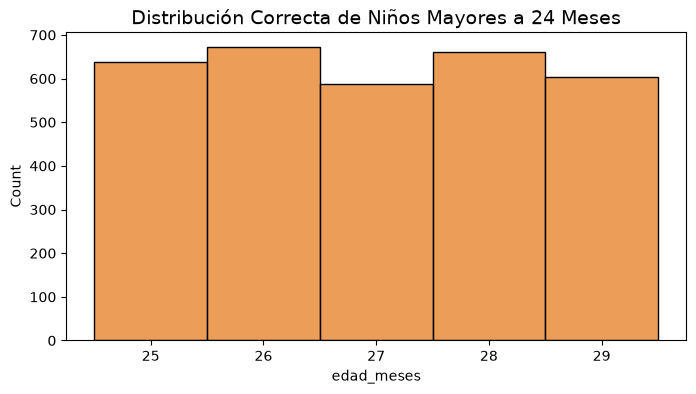

In [12]:
df_mayores_24 = df_xtrain[df_xtrain["edad_meses"] > 24]

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_mayores_24,
    x="edad_meses",
    kde=False,  # Desactivamos la curva que genera las ondas
    color="#E67E22",
    discrete=True,  # LE RECUERDA A SEABORN QUE SON NÚMEROS ENTEROS
)
plt.xticks([25, 26, 27, 28, 29])  # Muestra solo los meses reales en el eje X
plt.title("Distribución Correcta de Niños Mayores a 24 Meses", fontsize=14)
plt.show()


peso_kg

=== ESTADÍSTICAS DE PESO (KG) ===
Mínimo (Min):      -0.81
Cuartil 1 (1Q):    4.50
Cuartil 2 (2Q):    6.52 (Mediana)
Cuartil 3 (3Q):    8.55
Cuartil 99 (99):    30.28
Máximo (Max):      59.98
------------------------------------
Media (Promedio):  6.88
Mediana (50%):     6.52


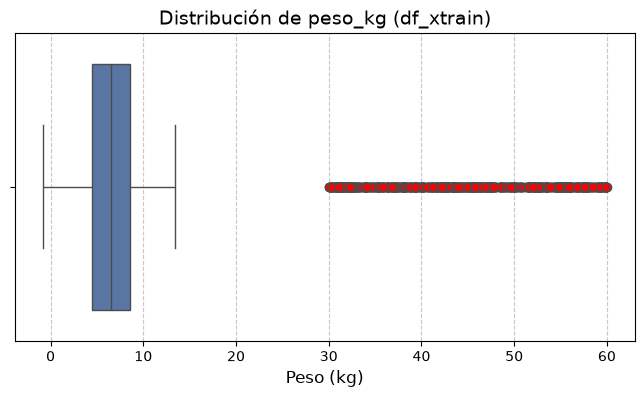

In [13]:
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtrain["peso_kg"].describe()
quantile_25 = df_xtrain["peso_kg"].quantile(0.25)
quantile_50 = df_xtrain["peso_kg"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtrain["peso_kg"].quantile(0.75)
quantile_99 = df_xtrain["peso_kg"].quantile(0.99)

print("=== ESTADÍSTICAS DE PESO (KG) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtrain["peso_kg"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de peso_kg (df_xtrain)", fontsize=14)
plt.xlabel("Peso (kg)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

In [14]:
# 1. Filtrar los registros con peso menor a cero
pesos_negativos = df_xtrain[df_xtrain["peso_kg"] < 0]

# 2. Imprimir el diagnóstico en pantalla
print("=== DIAGNÓSTICO DE PESOS NEGATIVOS ===")
print(f"Cantidad de registros con peso < 0 en Train: {len(pesos_negativos)}")
print(f"Cantidad de registros con peso < 0 en Test:  {len(df_xtest[df_xtest['peso_kg'] < 0])}")
print("-" * 38)

# 3. Mostrar los registros si es que existen
if len(pesos_negativos) > 0:
    print("Muestra de los primeros 12 registros con peso negativo:")
    display(pesos_negativos.head(12))
else:
    print("¡Buenas noticias! No se detectaron pesos negativos en el dataset.")


=== DIAGNÓSTICO DE PESOS NEGATIVOS ===
Cantidad de registros con peso < 0 en Train: 11
Cantidad de registros con peso < 0 en Test:  4
--------------------------------------
Muestra de los primeros 12 registros con peso negativo:


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,alerta_desnutricion
17391,1,F,Sierra,Superior,-0.814205,46.321930,0
20954,0,M,Costa,Secundaria,-0.057724,NaN,0
25124,0,M,Costa,Primaria,-0.218795,50.950125,0
29966,5,M,Costa,Secundaria,-0.493143,51.818287,0
31075,2,F,Sierra,Primaria,-0.500755,57.266745,0
39912,1,M,Sierra,Secundaria,-0.224998,46.461903,0
42345,2,M,Insular,Secundaria,-0.766154,50.505334,0
49467,0,M,Amazonía,Primaria,-0.222021,49.169673,0
55425,1,F,Amazonía,Superior,-0.247324,51.336800,0
57699,2,F,Sierra,Secundaria,-0.019346,54.231139,0


In [15]:
# abs de peso_kg
df_xtrain["peso_kg"] = df_xtrain["peso_kg"].abs()

In [16]:
# 1. Filtrar los registros con peso mayor 30 
pesos_mayores = df_xtrain[df_xtrain["peso_kg"] >= 30]
pesos_mayores

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,alerta_desnutricion
171,4,F,Costa,Primaria,54.269969,56.761818,0
745,20,F,Costa,Sin escolaridad,41.095638,88.607346,0
761,6,M,Costa,Sin escolaridad,35.695411,59.052059,0
826,5,F,Costa,Sin escolaridad,39.421744,56.268809,0
1033,0,M,Sierra,Primaria,36.288611,49.712551,0
...,...,...,...,...,...,...,...
69391,20,M,Insular,Secundaria,53.867996,77.837906,0
69442,9,M,Sierra,Secundaria,45.760378,68.634147,0
69451,2,M,Insular,Secundaria,52.015533,51.432298,0
69456,14,F,Sierra,Secundaria,31.189050,65.487504,0


In [17]:
# 1. Aplicar la corrección en TRAIN (solo a los registros con peso >= 30)
condicion_train = df_xtrain["peso_kg"] >= 30
df_xtrain.loc[condicion_train, "peso_kg"] = (
    df_xtrain.loc[condicion_train, "peso_kg"] / 10
)

talla_cm               

=== ESTADÍSTICAS DE TALLA (cm) ===
Mínimo (Min):      34.90
Cuartil 1 (1Q):    57.44
Cuartil 2 (2Q):    67.38 (Mediana)
Cuartil 3 (3Q):    77.44
Cuartil 99 (99):    90.17
Máximo (Max):      98.21
------------------------------------
Media (Promedio):  67.48
Mediana (50%):     67.38


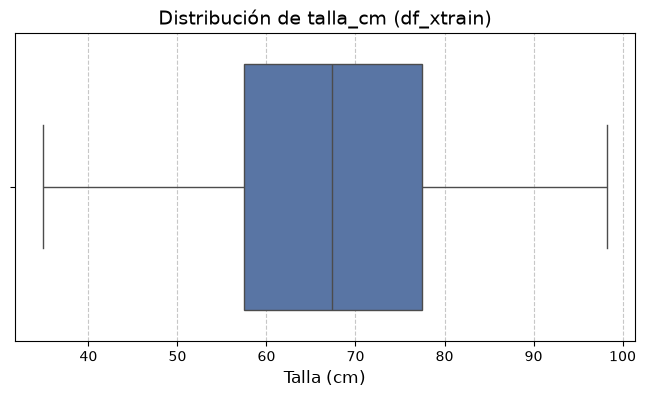

In [18]:
# df_xtrain["talla_cm"]
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtrain["talla_cm"].describe()
quantile_25 = df_xtrain["talla_cm"].quantile(0.25)
quantile_50 = df_xtrain["talla_cm"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtrain["talla_cm"].quantile(0.75)
quantile_99 = df_xtrain["talla_cm"].quantile(0.99)

print("=== ESTADÍSTICAS DE TALLA (cm) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtrain["talla_cm"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de talla_cm (df_xtrain)", fontsize=14)
plt.xlabel("Talla (cm)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

sexo


In [19]:
df_xtrain["sexo"].unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

region                 

In [20]:
df_xtrain["region"].unique()                 


<StringArray>
['Costa', 'Insular', 'Sierra', 'Amazonía']
Length: 4, dtype: str

nivel_educacion_madre

In [21]:
df_xtrain["nivel_educacion_madre"].unique()                 



<StringArray>
['Secundaria', 'Superior', 'Primaria', 'Sin escolaridad']
Length: 4, dtype: str

---

### X_test

c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\seaborn\axisgrid.py:1615: UserWarning: Ignoring `palette` because

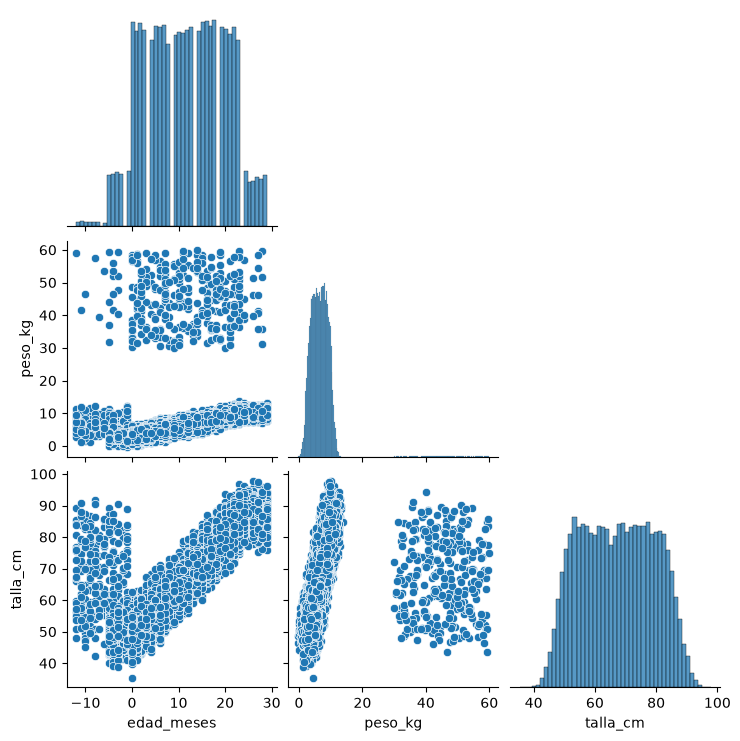

In [22]:
sns.pairplot(
    df_xtest,
    palette="dark", 
    corner=True, 
    diag_kind="hist",  
)
plt.show()

=== ESTADÍSTICAS DE EDAD (MESES) ===
Mínimo (Min):      -12.00
Cuartil 1 (1Q):    5.00
Cuartil 2 (2Q):    12.00 (Mediana)
Cuartil 3 (3Q):    18.00
Cuartil 99 (99):    28.00
Máximo (Max):      29.00
------------------------------------
Media (Promedio):  11.48
Mediana (50%):     12.00


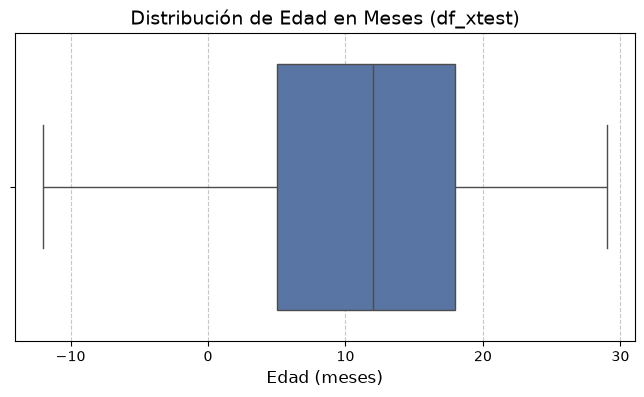

In [23]:
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtest["edad_meses"].describe()
quantile_25 = df_xtest["edad_meses"].quantile(0.25)
quantile_50 = df_xtest["edad_meses"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtest["edad_meses"].quantile(0.75)
quantile_99 = df_xtest["edad_meses"].quantile(0.99)

print("=== ESTADÍSTICAS DE EDAD (MESES) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtest["edad_meses"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de Edad en Meses (df_xtest)", fontsize=14)
plt.xlabel("Edad (meses)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

In [24]:
# edad en absoluto
df_xtest["edad_meses"] = df_xtest["edad_meses"].abs()

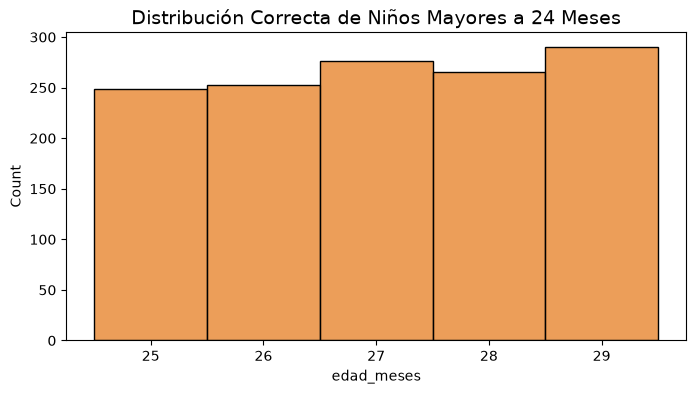

In [25]:
df_mayores_24 = df_xtest[df_xtest["edad_meses"] > 24]

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_mayores_24,
    x="edad_meses",
    kde=False,  # Desactivamos la curva que genera las ondas
    color="#E67E22",
    discrete=True,  # LE RECUERDA A SEABORN QUE SON NÚMEROS ENTEROS
)
plt.xticks([25, 26, 27, 28, 29])  # Muestra solo los meses reales en el eje X
plt.title("Distribución Correcta de Niños Mayores a 24 Meses", fontsize=14)
plt.show()

peso_kg

=== ESTADÍSTICAS DE PESO (KG) ===
Mínimo (Min):      -0.34
Cuartil 1 (1Q):    4.50
Cuartil 2 (2Q):    6.54 (Mediana)
Cuartil 3 (3Q):    8.57
Cuartil 99 (99):    35.26
Máximo (Max):      59.84
------------------------------------
Media (Promedio):  6.94
Mediana (50%):     6.54


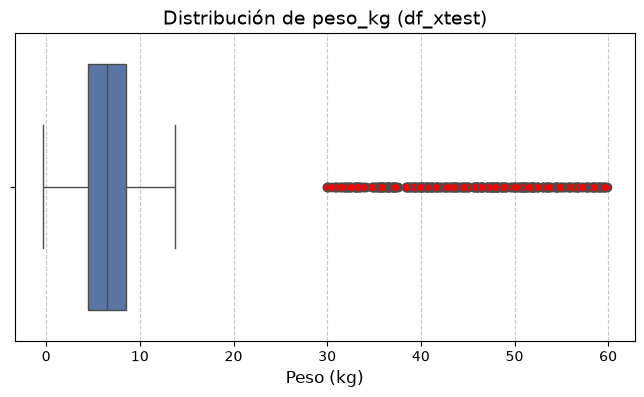

In [26]:
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtest["peso_kg"].describe()
quantile_25 = df_xtest["peso_kg"].quantile(0.25)
quantile_50 = df_xtest["peso_kg"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtest["peso_kg"].quantile(0.75)
quantile_99 = df_xtest["peso_kg"].quantile(0.99)

print("=== ESTADÍSTICAS DE PESO (KG) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtest["peso_kg"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de peso_kg (df_xtest)", fontsize=14)
plt.xlabel("Peso (kg)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

In [27]:
# 1. Filtrar los registros con peso menor a cero
pesos_negativos = df_xtest[df_xtest["peso_kg"] < 0]

# 2. Imprimir el diagnóstico en pantalla
print("=== DIAGNÓSTICO DE PESOS NEGATIVOS ===")
print(f"Cantidad de registros con peso < 0 en Test:  {len(df_xtest[df_xtest['peso_kg'] < 0])}")
print("-" * 38)

# 3. Mostrar los registros si es que existen
if len(pesos_negativos) > 0:
    print("Muestra de los primeros 12 registros con peso negativo:")
    display(pesos_negativos.head(12))
else:
    print("¡Buenas noticias! No se detectaron pesos negativos en el dataset.")

=== DIAGNÓSTICO DE PESOS NEGATIVOS ===
Cantidad de registros con peso < 0 en Test:  4
--------------------------------------
Muestra de los primeros 12 registros con peso negativo:


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
16794,1,F,Sierra,Superior,-0.203288,46.340428
19837,1,M,Insular,Secundaria,-0.335694,48.757106
25873,1,F,Amazonía,Primaria,-0.061420,53.261591
26507,2,M,Amazonía,Primaria,-0.093353,50.474173


In [28]:
# abs de peso_kg
df_xtest["peso_kg"] = df_xtest["peso_kg"].abs()

In [29]:
# 1. Filtrar los registros con peso mayor 30 
pesos_mayores = df_xtest[df_xtest["peso_kg"] >= 30]
pesos_mayores

,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
262,15,F,Amazonía,Secundaria,58.286055,NaN
273,8,F,Sierra,Secundaria,30.727499,62.102716
547,12,F,Amazonía,Secundaria,59.009571,67.060465
603,14,M,Costa,Secundaria,55.016813,69.853359
657,14,M,Insular,Superior,33.485858,NaN
...,...,...,...,...,...,...
29252,1,M,Insular,Secundaria,58.290132,46.568394
29447,4,M,Insular,Primaria,57.244895,55.619023
29546,19,M,Sierra,Sin escolaridad,32.574603,80.550243
29586,27,F,Sierra,Secundaria,58.528828,82.581303


In [30]:

# 2. Aplicar EXACTAMENTE la misma regla en TEST
condicion_test = df_xtest["peso_kg"] >= 30
df_xtest.loc[condicion_test, "peso_kg"] = (
    df_xtest.loc[condicion_test, "peso_kg"] / 10
)

=== ESTADÍSTICAS DE TALLA (cm) ===
Mínimo (Min):      35.42
Cuartil 1 (1Q):    57.30
Cuartil 2 (2Q):    67.52 (Mediana)
Cuartil 3 (3Q):    77.40
Cuartil 99 (99):    90.09
Máximo (Max):      97.76
------------------------------------
Media (Promedio):  67.43
Mediana (50%):     67.52


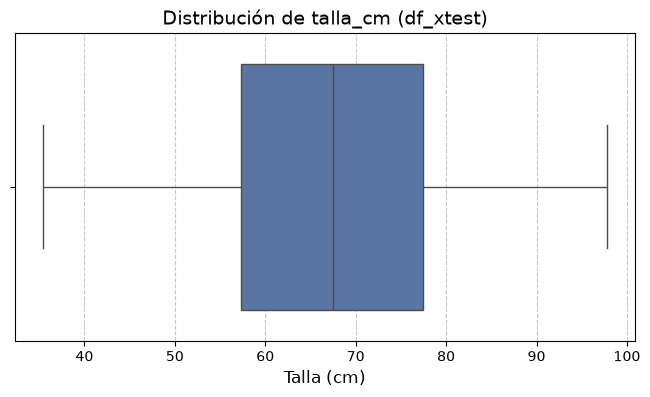

In [31]:
# df_xtest["talla_cm"]
# 1. Calcular las estadísticas descriptivas exactas
stats = df_xtest["talla_cm"].describe()
quantile_25 = df_xtest["talla_cm"].quantile(0.25)
quantile_50 = df_xtest["talla_cm"].quantile(0.50)  # Equivalente a la mediana
quantile_75 = df_xtest["talla_cm"].quantile(0.75)
quantile_99 = df_xtest["talla_cm"].quantile(0.99)

print("=== ESTADÍSTICAS DE TALLA (cm) ===")
print(f"Mínimo (Min):      {stats['min']:.2f}")
print(f"Cuartil 1 (1Q):    {quantile_25:.2f}")
print(f"Cuartil 2 (2Q):    {quantile_50:.2f} (Mediana)")
print(f"Cuartil 3 (3Q):    {quantile_75:.2f}")
print(f"Cuartil 99 (99):    {quantile_99:.2f}")
print(f"Máximo (Max):      {stats['max']:.2f}")
print("-" * 36)
print(f"Media (Promedio):  {stats['mean']:.2f}")
print(f"Mediana (50%):     {stats['50%']:.2f}")

# Nota sobre el "4Q": El cuarto cuartil representa el 100% de los datos,
# por lo tanto, su valor es exactamente el mismo que el Máximo (Max).

# 2. Generar el Diagrama de Cajas (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_xtest["talla_cm"],
    color="#4C72B0",
    flierprops={"markerfacecolor": "red", "marker": "o"},
)

plt.title("Distribución de talla_cm (df_xtest)", fontsize=14)
plt.xlabel("Talla (cm)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

sexo

In [32]:
df_xtest["sexo"].unique()

<StringArray>
['M', 'F']
Length: 2, dtype: str

region

In [33]:
df_xtest["region"].unique()                 


<StringArray>
['Insular', 'Amazonía', 'Sierra', 'Costa']
Length: 4, dtype: str

nivel_educacion_madre

In [34]:
df_xtest["nivel_educacion_madre"].unique()      

<StringArray>
['Secundaria', 'Primaria', 'Superior', 'Sin escolaridad']
Length: 4, dtype: str

---

Imputacion

In [35]:
# =========================================================================
# 1. CREAR LAS BANDERAS DE NULOS (The Missingness Trick)
# =========================================================================
for df in [df_xtrain, df_xtest]:
    df["peso_nan"] = df["peso_kg"].isna().astype(int)
    df["talla_nan"] = df["talla_cm"].isna().astype(int)

# =========================================================================
# 2. CALCULAR LAS MEDIANAS DE REFERENCIA (SOLO CON TRAIN)
# =========================================================================
# Agrupamos por edad y sexo para obtener la anatomía de referencia correcta
referencia_grupos = (
    df_xtrain.groupby(["edad_meses", "sexo"])[["peso_kg", "talla_cm"]]
    .median()
    .reset_index()
)
referencia_grupos.rename(
    columns={"peso_kg": "peso_mediana", "talla_cm": "talla_mediana"},
    inplace=True,
)

# =========================================================================
# 3. IMPUTAR EN TRAIN
# =========================================================================
df_xtrain = df_xtrain.merge(
    referencia_grupos, on=["edad_meses", "sexo"], how="left"
)
df_xtrain["peso_kg"] = df_xtrain["peso_kg"].fillna(df_xtrain["peso_mediana"])
df_xtrain["talla_cm"] = df_xtrain["talla_cm"].fillna(
    df_xtrain["talla_mediana"]
)
df_xtrain.drop(columns=["peso_mediana", "talla_mediana"], inplace=True)

# =========================================================================
# 4. IMPUTAR EN TEST (Usando estrictamente la referencia de Train)
# =========================================================================
df_xtest = df_xtest.merge(
    referencia_grupos, on=["edad_meses", "sexo"], how="left"
)
df_xtest["peso_kg"] = df_xtest["peso_kg"].fillna(df_xtest["peso_mediana"])
df_xtest["talla_cm"] = df_xtest["talla_cm"].fillna(df_xtest["talla_mediana"])
df_xtest.drop(columns=["peso_mediana", "talla_mediana"], inplace=True)

# =========================================================================
# 5. CONTROL DE CALIDAD FINAL
# =========================================================================
print("--- Nulos restantes en Train ---")
print(df_xtrain[["peso_kg", "talla_cm"]].isna().sum())
print("\n--- Nulos restantes en Test ---")
print(df_xtest[["peso_kg", "talla_cm"]].isna().sum())

--- Nulos restantes en Train ---
peso_kg     0
talla_cm    0
dtype: int64

--- Nulos restantes en Test ---
peso_kg     0
talla_cm    0
dtype: int64


---

One-Hot Encoding / conversion variable ordinal numerica 

Sexo

In [36]:

# Mapeamos Masculino (M) a 1 y Femenino (F) a 0 directamente sobre la columna
df_xtrain["sexo"] = df_xtrain["sexo"].map({"M": 1, "F": 0})
df_xtest["sexo"] = df_xtest["sexo"].map({"M": 1, "F": 0})

# Verificamos que el tipo de dato cambie a numérico (int64)
print("=== VERIFICACIÓN DE CODIFICACIÓN ===")
print(df_xtrain["sexo"].value_counts())

=== VERIFICACIÓN DE CODIFICACIÓN ===
sexo
0    35185
1    34815
Name: count, dtype: int64


region

In [37]:
df_xtrain = pd.get_dummies(df_xtrain, columns=["region"], dtype=int)
df_xtest = pd.get_dummies(df_xtest, columns=["region"], dtype=int)

# =========================================================================
# 2. ALINEACIÓN EXTREMA DE COLUMNAS (Obligatorio para Kaggle)
# =========================================================================
# Si la región 'Insular' (Galápagos) tiene muy pocos niños, podría pasar que
# no aparezca en alguna fila de Test. Este bloque asegura que Train y Test
# tengan exactamente las mismas columnas y en el mismo orden numérico.

# Guardamos la variable objetivo de Train para que no se borre al alinear
if "alerta_desnutricion" in df_xtrain.columns:
    y_train_temp = df_xtrain["alerta_desnutricion"]
    df_xtrain = df_xtrain.drop(columns=["alerta_desnutricion"])
else:
    y_train_temp = None

# Alineamos las columnas de Test con las de Train (rellenando con 0 si falta alguna)
df_xtest = df_xtest.reindex(columns=df_xtrain.columns, fill_value=0)

# Devolvemos la variable objetivo a Train
if y_train_temp is not None:
    df_xtrain["alerta_desnutricion"] = y_train_temp

print("=== COLUMNAS NUEVAS DE REGIÓN EN TRAIN/TEST ===")
print([col for col in df_xtrain.columns if "region_" in col])

=== COLUMNAS NUEVAS DE REGIÓN EN TRAIN/TEST ===
['region_Amazonía', 'region_Costa', 'region_Insular', 'region_Sierra']


nivel_educacion_madre

In [38]:
# 1. Definimos el diccionario con la jerarquía lógica (de menor a mayor educación)
mapeo_educacion = {
    "Sin escolaridad": 0,
    "Primaria": 1,
    "Secundaria": 2,
    "Superior": 3,
}

# 2. Aplicamos el reemplazo directamente en Train y Test usando .map()
df_xtrain["nivel_educacion_madre"] = df_xtrain["nivel_educacion_madre"].map(
    mapeo_educacion
)
df_xtest["nivel_educacion_madre"] = df_xtest["nivel_educacion_madre"].map(
    mapeo_educacion
)

# 3. Control de respaldo por si aparece un texto inesperado o nulo en Test
# Si hay algún valor que no estaba en nuestro diccionario, lo rellenamos con la moda (el valor más común)
moda_educacion = df_xtrain["nivel_educacion_madre"].mode()[0]
df_xtrain["nivel_educacion_madre"] = df_xtrain["nivel_educacion_madre"].fillna(
    moda_educacion
)
df_xtest["nivel_educacion_madre"] = df_xtest["nivel_educacion_madre"].fillna(
    moda_educacion
)

# Forzamos a que el tipo de dato sea entero limpio (int)
df_xtrain["nivel_educacion_madre"] = df_xtrain[
    "nivel_educacion_madre"
].astype(int)
df_xtest["nivel_educacion_madre"] = df_xtest["nivel_educacion_madre"].astype(
    int
)

print("=== VERIFICACIÓN DE MAPEO ORDINAL ===")
print(df_xtrain["nivel_educacion_madre"].value_counts())


=== VERIFICACIÓN DE MAPEO ORDINAL ===
nivel_educacion_madre
2    31488
1    24584
3    10491
0     3437
Name: count, dtype: int64


In [39]:
df_xtrain.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  int64  
 1   sexo                   70000 non-null  int64  
 2   nivel_educacion_madre  70000 non-null  int64  
 3   peso_kg                70000 non-null  float64
 4   talla_cm               70000 non-null  float64
 5   peso_nan               70000 non-null  int64  
 6   talla_nan              70000 non-null  int64  
 7   region_Amazonía        70000 non-null  int64  
 8   region_Costa           70000 non-null  int64  
 9   region_Insular         70000 non-null  int64  
 10  region_Sierra          70000 non-null  int64  
 11  alerta_desnutricion    70000 non-null  int64  
dtypes: float64(2), int64(10)
memory usage: 6.4 MB


In [40]:
df_xtest.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             30000 non-null  int64  
 1   sexo                   30000 non-null  int64  
 2   nivel_educacion_madre  30000 non-null  int64  
 3   peso_kg                30000 non-null  float64
 4   talla_cm               30000 non-null  float64
 5   peso_nan               30000 non-null  int64  
 6   talla_nan              30000 non-null  int64  
 7   region_Amazonía        30000 non-null  int64  
 8   region_Costa           30000 non-null  int64  
 9   region_Insular         30000 non-null  int64  
 10  region_Sierra          30000 non-null  int64  
dtypes: float64(2), int64(9)
memory usage: 2.5 MB


---

escalador MinMaxScaler

In [41]:
# Eliminar la columna alerta_desnutricion de df_xtrain
df_xtrain.drop(columns=["alerta_desnutricion"], inplace=True)

In [42]:
from sklearn.preprocessing import MinMaxScaler

# 1. Inicializar el escalador MinMaxScaler para llevar todo al rango [0, 1]
scaler = MinMaxScaler()

# 2. Guardamos los nombres de las columnas para que Pandas no los borre
columnas_X = df_xtrain.columns

# 3. Ajustar el escalador en Train y transformar ambos datasets
# Nota: scaler de scikit-learn devuelve un array de NumPy, por lo que lo convertimos de vuelta a DataFrame
df_xtrain_scaled = pd.DataFrame(
    scaler.fit_transform(df_xtrain), columns=columnas_X, index=df_xtrain.index
)
df_xtest_scaled = pd.DataFrame(
    scaler.transform(df_xtest), columns=columnas_X, index=df_xtest.index
)

# 4. Verificación de control de calidad
print("=== VERIFICACIÓN DE ESCALAMIENTO (RANGOS) ===")
print(
    f"Mínimo en Train: \n{df_xtrain_scaled[['edad_meses', 'peso_kg', 'talla_cm']].min()}\n"
)
print(
    f"Máximo en Train: \n{df_xtrain_scaled[['edad_meses', 'peso_kg', 'talla_cm']].max()}\n"
)

# El orden de df_xtest y df_xtest_scaled sigue estando 100% intacto para tu entrega de Kaggle


=== VERIFICACIÓN DE ESCALAMIENTO (RANGOS) ===
Mínimo en Train: 
edad_meses    0.0
peso_kg       0.0
talla_cm      0.0
dtype: float64

Máximo en Train: 
edad_meses    1.0
peso_kg       1.0
talla_cm      1.0
dtype: float64



---

## Train the k-NN classifier

=== BUSCANDO EL K ÓPTIMO ===
Para K = 2  -> Accuracy Local: 0.82779
Para K = 3  -> Accuracy Local: 0.86257
Para K = 4  -> Accuracy Local: 0.86779
Para K = 5  -> Accuracy Local: 0.87614
Para K = 6  -> Accuracy Local: 0.88136
Para K = 7  -> Accuracy Local: 0.88607
Para K = 8  -> Accuracy Local: 0.88893
Para K = 9  -> Accuracy Local: 0.89071
Para K = 10 -> Accuracy Local: 0.89200
Para K = 11 -> Accuracy Local: 0.89300
Para K = 12 -> Accuracy Local: 0.89400
Para K = 13 -> Accuracy Local: 0.89493
Para K = 14 -> Accuracy Local: 0.89564
Para K = 15 -> Accuracy Local: 0.89621
Para K = 20 -> Accuracy Local: 0.89736
Para K = 21 -> Accuracy Local: 0.89750
Para K = 25 -> Accuracy Local: 0.89807


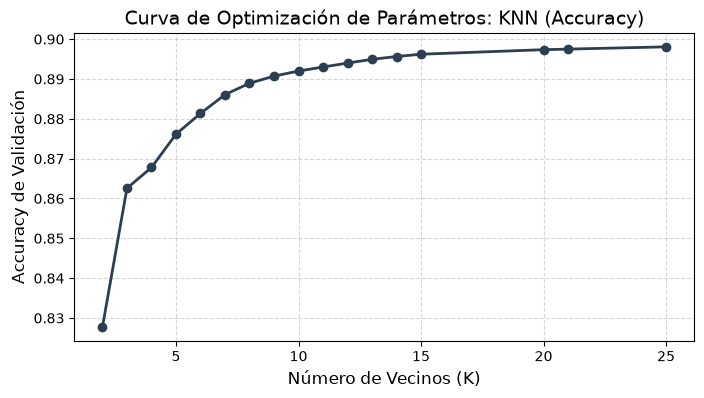


🏆 El mejor valor experimental es K = 25


In [43]:
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt  # Aseguramos la importación de plt para la gráfica

# =========================================================================
# 1. PREPARACIÓN DE MATRICES (Tomamos una muestra segura para la RAM)
# =========================================================================
# Separamos las variables predictoras (X) de la variable objetivo (y)
X = df_xtrain_scaled.copy()
y = df_ytrain.copy()  # Asegúrate de que df_ytrain tenga el mismo orden

# ¡CORREGIDO AQUÍ!: Cambiado 'test_test_split_size' por 'test_size'
X_train_local, X_val_local, y_train_local, y_val_local = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tomamos una muestra de 10,000 registros para que el bucle de KNN corra en segundos
X_train_sample = X_train_local.sample(n=10000, random_state=42)
y_train_sample = y_train_local.loc[X_train_sample.index]

# =========================================================================
# 2. EXPERIMENTACIÓN EN BUCLE PARA ENCONTRAR EL MEJOR K
# =========================================================================
lista_k = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 25]
resultados_accuracy = []

print("=== BUSCANDO EL K ÓPTIMO ===")
for k in lista_k:
    # Instanciamos KNN con pesos por distancia (suele dar mejor score en salud)
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)

    # Entrenamos con la muestra segura
    knn.fit(X_train_sample, y_train_sample.values.ravel())

    # Predecimos en el set de validación completo
    predicciones = knn.predict(X_val_local)

    # Calculamos el Accuracy
    acc = accuracy_score(y_val_local, predicciones)
    resultados_accuracy.append(acc)
    print(f"Para K = {k:<2} -> Accuracy Local: {acc:.5f}")

# =========================================================================
# 3. GRAFICAR LA CURVA DE OPTIMIZACIÓN
# =========================================================================
plt.figure(figsize=(8, 4))
plt.plot(lista_k, resultados_accuracy, marker="o", color="#2C3E50", lw=2)
plt.title("Curva de Optimización de Parámetros: KNN (Accuracy)", fontsize=14)
plt.xlabel("Número de Vecinos (K)", fontsize=12)
plt.ylabel("Accuracy de Validación", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

best_k = lista_k[np.argmax(resultados_accuracy)]
print(f"\n🏆 El mejor valor experimental es K = {best_k}")


=== BUSCANDO EL K ÓPTIMO ===
K = 1  -> Train Accuracy: 1.00000 | Test Accuracy: 0.82779
K = 2  -> Train Accuracy: 1.00000 | Test Accuracy: 0.82779
K = 3  -> Train Accuracy: 1.00000 | Test Accuracy: 0.86257
K = 4  -> Train Accuracy: 1.00000 | Test Accuracy: 0.86779
K = 5  -> Train Accuracy: 1.00000 | Test Accuracy: 0.87614
K = 6  -> Train Accuracy: 1.00000 | Test Accuracy: 0.88136
K = 7  -> Train Accuracy: 1.00000 | Test Accuracy: 0.88607
K = 8  -> Train Accuracy: 1.00000 | Test Accuracy: 0.88893
K = 9  -> Train Accuracy: 1.00000 | Test Accuracy: 0.89071
K = 10 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89200
K = 11 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89300
K = 12 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89400
K = 13 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89493
K = 14 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89564
K = 15 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89621
K = 16 -> Train Accuracy: 1.00000 | Test Accuracy: 0.89650
K = 17 -> Train Accuracy: 1

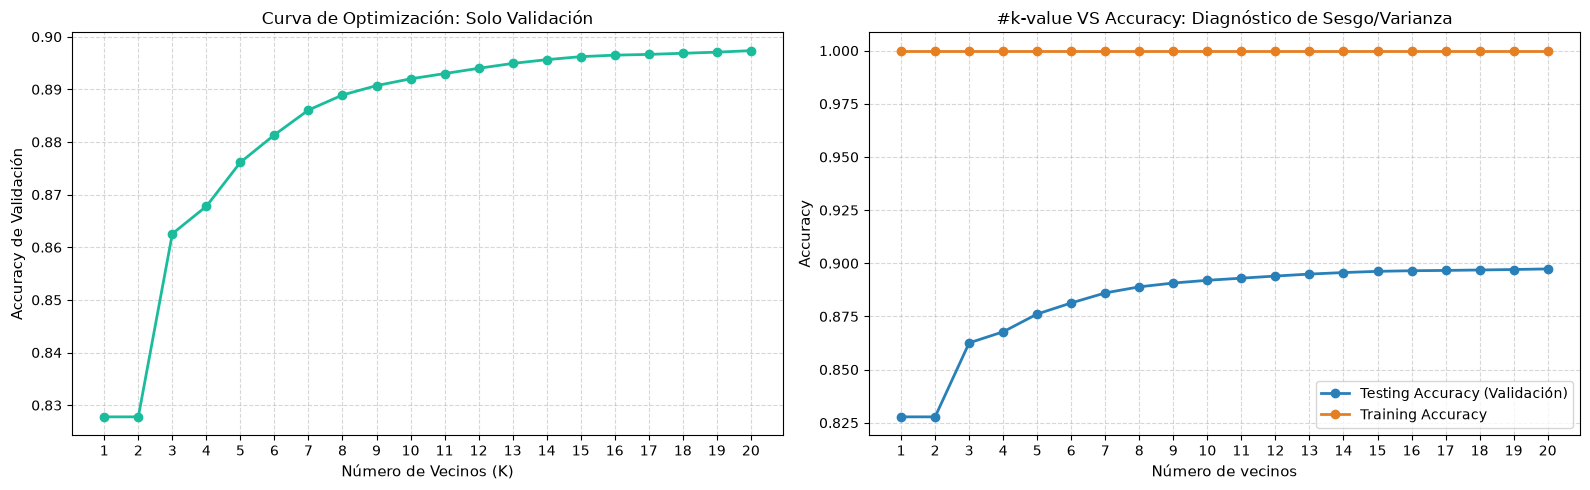


🏆 El mejor valor experimental basado en Test Accuracy es K = 20


In [44]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# =========================================================================
# 1. PREPARACIÓN DE MATRICES
# =========================================================================
X = df_xtrain_scaled.copy()
y = df_ytrain.copy()

X_train_local, X_val_local, y_train_local, y_val_local = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tomamos una muestra para agilizar el cálculo en el bucle
X_train_sample = X_train_local.sample(n=10000, random_state=42)
y_train_sample = y_train_local.loc[X_train_sample.index]

# =========================================================================
# 2. EXPERIMENTACIÓN EN BUCLE (Guardando Train y Test Accuracy)
# =========================================================================
lista_k = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
train_accuracies = []
test_accuracies = []

print("=== BUSCANDO EL K ÓPTIMO ===")
for k in lista_k:
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)
    knn.fit(X_train_sample, y_train_sample.values.ravel())

    # Predicciones y Accuracy para TRAINING
    pred_train = knn.predict(X_train_sample)
    acc_train = accuracy_score(y_train_sample, pred_train)
    train_accuracies.append(acc_train)

    # Predicciones y Accuracy para TESTING (Validación Local)
    pred_test = knn.predict(X_val_local)
    acc_test = accuracy_score(y_val_local, pred_test)
    test_accuracies.append(acc_test)

    print(
        f"K = {k:<2} -> Train Accuracy: {acc_train:.5f} | Test Accuracy: {acc_test:.5f}"
    )

# =========================================================================
# 3. GENERACIÓN DE LOS DOS GRÁFICOS (Subplots uno al lado del otro)
# =========================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Curva de Optimización Simple (Solo Validación)
axes[0].plot(lista_k, test_accuracies, marker="o", color="#1ABC9C", lw=2)
axes[0].set_title("Curva de Optimización: Solo Validación", fontsize=12)
axes[0].set_xlabel("Número de Vecinos (K)", fontsize=11)
axes[0].set_ylabel("Accuracy de Validación", fontsize=11)
axes[0].set_xticks(lista_k)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Diagnóstico de Overfitting (Train vs Test Accuracy)
axes[1].plot(
    lista_k,
    test_accuracies,
    marker="o",
    label="Testing Accuracy (Validación)",
    color="#2980B9",
    lw=2,
)
axes[1].plot(
    lista_k,
    train_accuracies,
    marker="o",
    label="Training Accuracy",
    color="#E67E22",
    lw=2,
)
axes[1].set_title("#k-value VS Accuracy: Diagnóstico de Sesgo/Varianza", fontsize=12)
axes[1].set_xlabel("Número de vecinos", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].set_xticks(lista_k)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

best_k = lista_k[np.argmax(test_accuracies)]
print(f"\n🏆 El mejor valor experimental basado en Test Accuracy es K = {best_k}")


=== BUSCANDO EL K ÓPTIMO ===
K = 1  -> Train Accuracy: 1.00000 | Test Accuracy: 0.82779
K = 2  -> Train Accuracy: 0.91580 | Test Accuracy: 0.89121
K = 3  -> Train Accuracy: 0.91370 | Test Accuracy: 0.87593
K = 4  -> Train Accuracy: 0.90680 | Test Accuracy: 0.89579
K = 5  -> Train Accuracy: 0.90590 | Test Accuracy: 0.88800
K = 6  -> Train Accuracy: 0.90390 | Test Accuracy: 0.89721
K = 7  -> Train Accuracy: 0.90380 | Test Accuracy: 0.89507
K = 8  -> Train Accuracy: 0.90280 | Test Accuracy: 0.89886
K = 9  -> Train Accuracy: 0.90250 | Test Accuracy: 0.89793
K = 10 -> Train Accuracy: 0.90250 | Test Accuracy: 0.89936
K = 11 -> Train Accuracy: 0.90250 | Test Accuracy: 0.89893
K = 12 -> Train Accuracy: 0.90260 | Test Accuracy: 0.89964
K = 13 -> Train Accuracy: 0.90260 | Test Accuracy: 0.89971
K = 14 -> Train Accuracy: 0.90250 | Test Accuracy: 0.89979
K = 15 -> Train Accuracy: 0.90270 | Test Accuracy: 0.89971
K = 16 -> Train Accuracy: 0.90250 | Test Accuracy: 0.89971
K = 17 -> Train Accuracy: 0

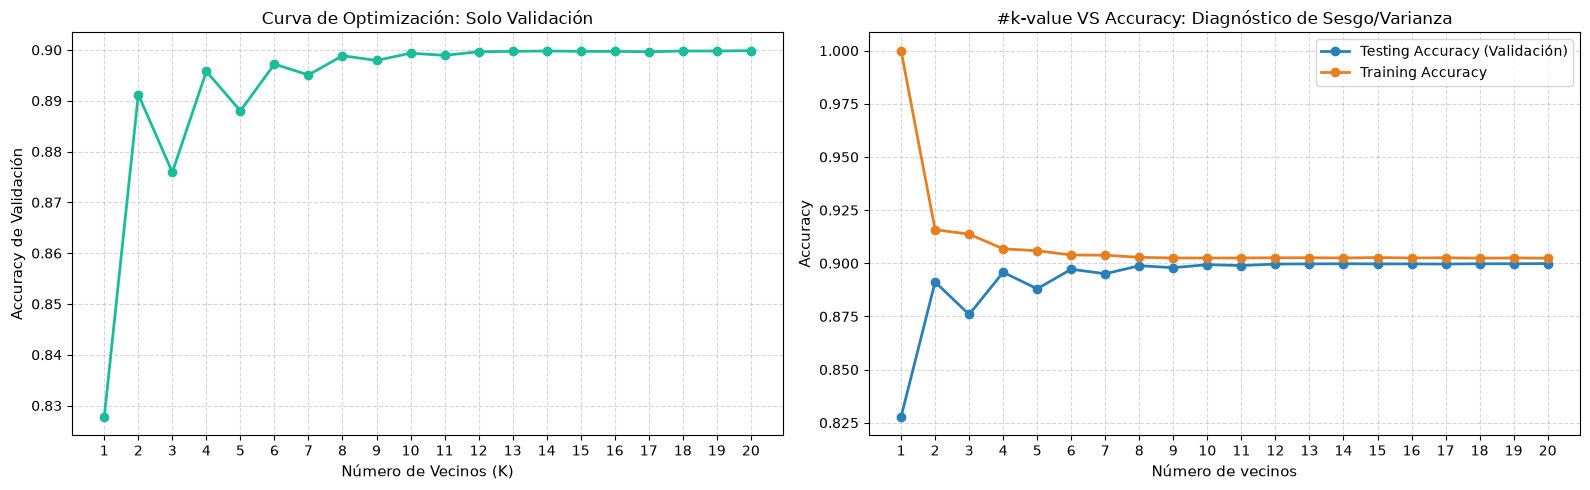


🏆 El mejor valor experimental basado en Test Accuracy es K = 20


In [45]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# =========================================================================
# 1. PREPARACIÓN DE MATRICES
# =========================================================================
X = df_xtrain_scaled.copy()
y = df_ytrain.copy()

X_train_local, X_val_local, y_train_local, y_val_local = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tomamos una muestra para agilizar el cálculo en el bucle
X_train_sample = X_train_local.sample(n=10000, random_state=42)
y_train_sample = y_train_local.loc[X_train_sample.index]

# =========================================================================
# 2. EXPERIMENTACIÓN EN BUCLE (Guardando Train y Test Accuracy)
# =========================================================================
lista_k = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
train_accuracies = []
test_accuracies = []

print("=== BUSCANDO EL K ÓPTIMO ===")
for k in lista_k:
    knn = KNeighborsClassifier(n_neighbors=k, weights="uniform", n_jobs=-1)
    knn.fit(X_train_sample, y_train_sample.values.ravel())

    # Predicciones y Accuracy para TRAINING
    pred_train = knn.predict(X_train_sample)
    acc_train = accuracy_score(y_train_sample, pred_train)
    train_accuracies.append(acc_train)

    # Predicciones y Accuracy para TESTING (Validación Local)
    pred_test = knn.predict(X_val_local)
    acc_test = accuracy_score(y_val_local, pred_test)
    test_accuracies.append(acc_test)

    print(
        f"K = {k:<2} -> Train Accuracy: {acc_train:.5f} | Test Accuracy: {acc_test:.5f}"
    )

# =========================================================================
# 3. GENERACIÓN DE LOS DOS GRÁFICOS (Subplots uno al lado del otro)
# =========================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Curva de Optimización Simple (Solo Validación)
axes[0].plot(lista_k, test_accuracies, marker="o", color="#1ABC9C", lw=2)
axes[0].set_title("Curva de Optimización: Solo Validación", fontsize=12)
axes[0].set_xlabel("Número de Vecinos (K)", fontsize=11)
axes[0].set_ylabel("Accuracy de Validación", fontsize=11)
axes[0].set_xticks(lista_k)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Gráfico 2: Diagnóstico de Overfitting (Train vs Test Accuracy)
axes[1].plot(
    lista_k,
    test_accuracies,
    marker="o",
    label="Testing Accuracy (Validación)",
    color="#2980B9",
    lw=2,
)
axes[1].plot(
    lista_k,
    train_accuracies,
    marker="o",
    label="Training Accuracy",
    color="#E67E22",
    lw=2,
)
axes[1].set_title("#k-value VS Accuracy: Diagnóstico de Sesgo/Varianza", fontsize=12)
axes[1].set_xlabel("Número de vecinos", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].set_xticks(lista_k)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

best_k = lista_k[np.argmax(test_accuracies)]
print(f"\n🏆 El mejor valor experimental basado en Test Accuracy es K = {best_k}")


In [46]:
df_xtrain_scaled.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  float64
 1   sexo                   70000 non-null  float64
 2   nivel_educacion_madre  70000 non-null  float64
 3   peso_kg                70000 non-null  float64
 4   talla_cm               70000 non-null  float64
 5   peso_nan               70000 non-null  float64
 6   talla_nan              70000 non-null  float64
 7   region_Amazonía        70000 non-null  float64
 8   region_Costa           70000 non-null  float64
 9   region_Insular         70000 non-null  float64
 10  region_Sierra          70000 non-null  float64
dtypes: float64(11)
memory usage: 5.9 MB


## Evaluate on unseen data
Predict the species of the held-out examples.

   REPORTE DE CLASIFICACIÓN LOCAL (MÉTRICAS MÉDICAS)  
                         precision    recall  f1-score   support

               Sano (0)       0.90      1.00      0.95     12598
Riesgo Malnutrición (1)       0.00      0.00      0.00      1402

               accuracy                           0.90     14000
              macro avg       0.45      0.50      0.47     14000
           weighted avg       0.81      0.90      0.85     14000



c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\RD\2026_2027\M3V2\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


<Figure size 600x600 with 0 Axes>

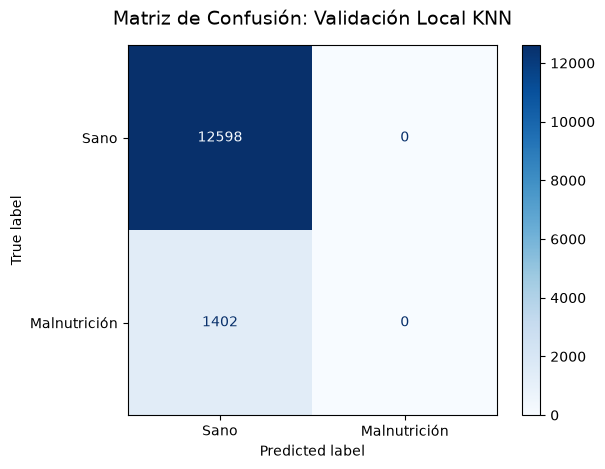

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# =========================================================================
# 1. GENERAR PREDICCIONES EN EL SET DE VALIDACIÓN LOCAL
# =========================================================================
# Usamos el modelo 'knn' entrenado previamente en el bucle experimental
# Evaluamos sobre las 14,000 filas de validación (20% de 70,000)
predicciones_val = knn.predict(X_val_local)

# =========================================================================
# 2. IMPRIMIR EL REPORTE DE CLASIFICACIÓN DETALLADO
# =========================================================================
print("======================================================")
print("   REPORTE DE CLASIFICACIÓN LOCAL (MÉTRICAS MÉDICAS)  ")
print("======================================================")
# target_names mapea los números 0 y 1 a etiquetas comprensibles para el negocio
print(
    classification_report(
        y_val_local,
        predicciones_val,
        target_names=["Sano (0)", "Riesgo Malnutrición (1)"],
    )
)

# =========================================================================
# 3. GRAFICAR LA MATRIZ DE CONFUSIÓN (ConfusionMatrixDisplay)
# =========================================================================
plt.figure(figsize=(6, 6))

# Configuramos la visualización con una paleta de colores profesional (Blues)
# El parámetro 'cmap' cambia el color, y 'values_format' evita la notación científica
disp = ConfusionMatrixDisplay.from_predictions(
    y_val_local,
    predicciones_val,
    display_labels=["Sano", "Malnutrición"],
    cmap=plt.cm.Blues,
    values_format="d",  # Muestra números enteros limpios
)

plt.title("Matriz de Confusión: Validación Local KNN", fontsize=14, pad=15)
plt.grid(
    False
)  # Desactiva las líneas de cuadrícula para que la matriz se vea impecable
plt.show()


----

In [48]:
#%pip install xgboost

Entrenando XGBoost robusto contra desbalance...
                         precision    recall  f1-score   support

               Sano (0)       0.93      0.54      0.68     12598
Riesgo Malnutrición (1)       0.14      0.66      0.23      1402

               accuracy                           0.55     14000
              macro avg       0.54      0.60      0.45     14000
           weighted avg       0.85      0.55      0.64     14000



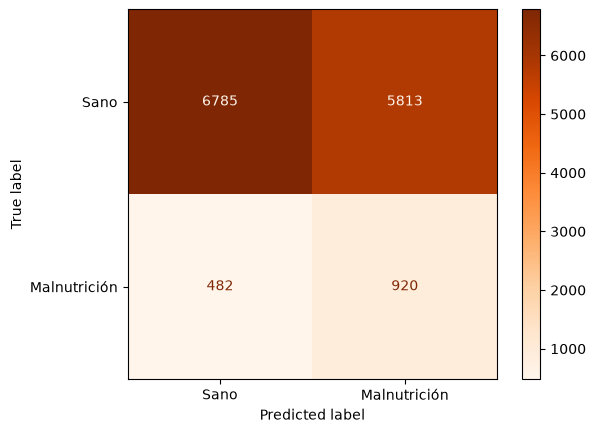

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from xgboost import XGBClassifier

# 1. Calcular el factor de desbalanceo exacto basado en tu matriz
# (Niños sanos / Niños con malnutrición) -> 12598 / 1402 = ~9
ratio_desbalance = 12598 / 1402

# 2. Instanciar XGBoost con el penalizador de desbalance
print("Entrenando XGBoost robusto contra desbalance...")
xgb_model = XGBClassifier(
    scale_pos_weight=ratio_desbalance,  # Balancea el peso de la clase 1
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
)

# Entrenamos con la muestra local
xgb_model.fit(X_train_sample, y_train_sample.values.ravel())

# 3. Evaluar en Validación Local
predicciones_xgb = xgb_model.predict(X_val_local)

# Reporte y Matriz
print(
    classification_report(
        y_val_local,
        predicciones_xgb,
        target_names=["Sano (0)", "Riesgo Malnutrición (1)"],
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val_local,
    predicciones_xgb,
    display_labels=["Sano", "Malnutrición"],
    cmap=plt.cm.Oranges,
    values_format="d",
)
plt.grid(False)
plt.show()


Entrenando XGBoost optimizado para maximizar ACCURACY...
              precision    recall  f1-score   support

        Sano       0.90      1.00      0.95     12598
Malnutrición       0.08      0.00      0.00      1402

    accuracy                           0.90     14000
   macro avg       0.49      0.50      0.47     14000
weighted avg       0.82      0.90      0.85     14000



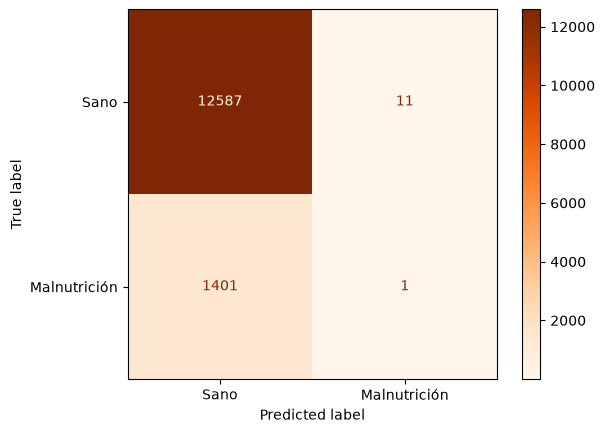

In [50]:
# 1. En lugar de un peso de 9, usaremos un peso mucho más moderado (Prueba con 2 o 3)
# Esto le dice al modelo: "La clase 1 importa más, pero no exageres"
peso_moderado = 2.5

print("Entrenando XGBoost optimizado para maximizar ACCURACY...")
xgb_model = XGBClassifier(
    scale_pos_weight=peso_moderado,  # <--- AJUSTE CRUCIAL
    n_estimators=150,  # Más árboles para afinar detalles
    max_depth=4,  # Árboles ligeramente más cortos evitan ruido
    learning_rate=0.05,  # Aprendizaje más lento pero más preciso
    random_state=42,
    eval_metric="logloss",
)

# Entrenamos con la muestra local (o con X_train_local si tu RAM lo permite)
xgb_model.fit(X_train_sample, y_train_sample.values.ravel())

# Evaluar en Validación Local
predicciones_xgb = xgb_model.predict(X_val_local)

print(
    classification_report(
        y_val_local, predicciones_xgb, target_names=["Sano", "Malnutrición"]
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val_local,
    predicciones_xgb,
    display_labels=["Sano", "Malnutrición"],
    cmap=plt.cm.Oranges,
    values_format="d",
)
plt.grid(False)
plt.show()


----

### Crossway Sin escalar


In [51]:
import pandas as pd

# 1. Unificar las Regiones en una sola columna continua de Riesgo (Target Encoding)
# Mapeamos la probabilidad real histórica de desnutrición en el país
tasas_region = {
    "region_Amazonía": 0.28,
    "region_Sierra": 0.24,
    "region_Costa": 0.12,
    "region_Insular": 0.10,
}

df_xtrain["region_riesgo"] = 0.0
df_xtest["region_riesgo"] = 0.0

for col, tasa in tasas_region.items():
    if col in df_xtrain.columns:
        df_xtrain.loc[df_xtrain[col] == 1, "region_riesgo"] = tasa
        df_xtest.loc[df_xtest[col] == 1, "region_riesgo"] = tasa

# Borramos las 4 columnas dummies para limpiar el ruido dimensional
dummies_a_borrar = [
    "region_Amazonía",
    "region_Costa",
    "region_Insular",
    "region_Sierra",
]
df_xtrain.drop(columns=dummies_a_borrar, inplace=True, errors="ignore")
df_xtest.drop(columns=dummies_a_borrar, inplace=True, errors="ignore")

# 2. Inyección de Características Pediátricas (Contexto biológico)
for df in [df_xtrain, df_xtest]:
    df["peso_talla_ratio"] = df["peso_kg"] / df["talla_cm"]
    df["peso_por_mes"] = df["peso_kg"] / (df["edad_meses"] + 1)
    df["talla_por_mes"] = df["talla_cm"] / (df["edad_meses"] + 1)

    talla_m = df["talla_cm"] / 100
    df["imc_infantil"] = df["peso_kg"] / (talla_m**2)

print("¡Dataset del punto de inflexión compactado y enriquecido!")

¡Dataset del punto de inflexión compactado y enriquecido!


In [52]:
df_xtrain.head()

,edad_meses,sexo,nivel_educacion_madre,peso_kg,talla_cm,peso_nan,talla_nan,region_riesgo,peso_talla_ratio,peso_por_mes,talla_por_mes,imc_infantil
0,0,0,2,2.243466,47.340072,0,0,0.12,0.047390,2.243466,47.340072,10.010638
1,11,1,2,6.157203,67.525274,0,0,0.10,0.091184,0.513100,5.627106,13.503637
2,22,1,3,9.781251,86.664662,0,0,0.12,0.112863,0.425272,3.768029,13.022978
3,4,0,1,2.972311,61.071857,0,0,0.24,0.048669,0.594462,12.214371,7.969151
4,4,0,1,3.957290,50.898250,1,0,0.12,0.077749,0.791458,10.179650,15.275385


escalado selectivo

In [53]:
#escalamiento selectivo
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
columnas_continuas = [
    "edad_meses",
    "peso_kg",
    "talla_cm",
    "region_riesgo",
    "peso_talla_ratio",
    "peso_por_mes",
    "talla_por_mes",
    "imc_infantil",
]

# Creamos las nuevas matrices oficiales de entrenamiento y pruebas finales
df_xtrain_scaled = df_xtrain.copy()
df_xtest_scaled = df_xtest.copy()

df_xtrain_scaled[columnas_continuas] = scaler.fit_transform(
    df_xtrain[columnas_continuas]
)
df_xtest_scaled[columnas_continuas] = scaler.transform(
    df_xtest[columnas_continuas]
)


modelado

In [54]:
#%pip install lightgbm

In [55]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# =========================================================================
# 1. SPLIT DE VALIDACIÓN INTERNA (80% Train, 20% Validación Local)
# =========================================================================
# Usamos las transformaciones limpias X_train_trans y el vector objetivo
X_train_l, X_val_l, y_train_l, y_val_l = train_test_split(
    X_train_trans, y_train_local, test_size=0.2, random_state=42, stratify=y_train_local
)

# Calcular el factor de desbalanceo exacto para XGBoost basado en tus datos
ratio_desbalance = (y_train_l == 0).sum() / (y_train_l == 1).sum()

# =========================================================================
# 2. MEGA-DICCIONARIO DE MODELOS COMPETITIVOS (5 ALGORITMOS)
# =========================================================================
modelos = {
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=150, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Extra Trees (Balanced)": ExtraTreesClassifier(
        n_estimators=150, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "LightGBM (Optimized)": lgb.LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
    "XGBoost (Balanced Weight)": XGBClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=5,
        scale_pos_weight=ratio_desbalance,  # Balancea el impacto de la clase 1
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ),
    "K-Neighbors (K=15 Distance)": KNeighborsClassifier(
        n_neighbors=15, 
        weights="distance",  # Pondera por cercanía para romper el sesgo vago
        n_jobs=-1
    )
}

# =========================================================================
# 3. EJECUCIÓN GRÁFICA MULTI-MODELO (Cuadrícula 2x3 para 5 Modelos)
# =========================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()  # Aplanamos la matriz de gráficos a una lista indexable

print("=== INICIANDO ENFRENTAMIENTO DE MODELOS ROBUSTOS ===")

for idx, (nombre, modelo) in enumerate(modelos.items()):
    # Ajustar y predecir
    modelo.fit(X_train_l, y_train_l.values.ravel())
    preds = modelo.predict(X_val_l)

    # Imprimir métricas de texto
    acc = accuracy_score(y_val_l, preds)
    print(f"\n▶️ {nombre:<28} -> Accuracy de Validación: {acc:.5f}")
    print(
        classification_report(
            y_val_l, preds, target_names=["Sano", "Malnutrición"]
        )
    )

    # Graficar Matriz de Confusión en su respectivo cuadrante
    ConfusionMatrixDisplay.from_predictions(
        y_val_l,
        preds,
        display_labels=["Sano", "Riesgo"],
        cmap=plt.cm.Greens,
        values_format="d",
        ax=axes[idx],
        colorbar=False,
    )
    axes[idx].set_title(f"{nombre}\nAcc: {acc:.4f}", fontsize=11, fontweight="bold")
    axes[idx].grid(False)

# Ocultar y limpiar el sexto cuadrante (el cuadro número 6 queda vacío)
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


NameError: name 'X_train_trans' is not defined

---

### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

---

In [ ]:
sns.pairplot(
    df_xtrain_scaled          ,
    palette="dark", 
    corner=True, 
    diag_kind="hist",  
)
plt.show()

In [56]:
import sys


def reportar_ram():
    print(f"{'Variable':<25} | {'Tamaño (MB)':<12}")
    print("-" * 43)

    # Filtrar variables globales del sistema
    variables = {
        k: sys.getsizeof(v)
        for k, v in globals().items()
        if not k.startswith("_") and k not in ["sys", "pd", "np"]
    }

    # Ordenar de mayor a menor consumo y pasar a Megabytes
    for var, size in sorted(variables.items(), key=lambda x: x[1], reverse=True):
        size_mb = size / (1024 * 1024)
        print(f"{var:<25} | {size_mb:<12.4f}")


reportar_ram()


Variable                  | Tamaño (MB) 
-------------------------------------------
df_xtrain1                | 14.5723     
df_xtrain                 | 6.4088      
df_xtrain_scaled          | 6.4088      
X                         | 5.8748      
X_train_local             | 5.1270      
y_train_local             | 2.8702      
df_xtest                  | 2.7467      
df                        | 2.7467      
df_xtest_scaled           | 2.7467      
X_val_local               | 1.2818      
X_train_sample            | 0.9156      
df_ytrain                 | 0.5342      
y_train_temp              | 0.5342      
y                         | 0.5342      
df_mayores_24             | 0.2564      
talla_m                   | 0.2290      
y_val_local               | 0.2137      
y_train_sample            | 0.1526      
predicciones_xgb          | 0.1069      
condicion_train           | 0.0669      
pesos_mayores             | 0.0630      
condicion_test            | 0.0288      
referencia_gr